# KDE de tiempos de viaje en auto: OD original vs. Toronto

Compara la distribución de tiempos de viaje en auto de dos escenarios usando una **KDE ponderada por número de viajes**:

- 🔵 **OD original**: demanda OD por periodo (Auto) × skims **TTC** de auto (`Skims_061126`, vienen anchas)
- 🟢 **Toronto (RUN 191126)**: demanda de auto por periodo × skims **aivtt** (vienen largas)

**Pasos para usarlo**
1. Llena las rutas y nombres de columnas en la celda ** Configuración**.
2. Corre la sección ** Revisión de archivos** y verifica que cada periodo agarró el archivo correcto.
3. Corre todo lo demás.

## Configuración

In [12]:
from pathlib import Path

# ---------------------------------------------------------------
# 1) RUTAS A LAS CARPETAS
# ---------------------------------------------------------------
# 🔵 OD original
DIR_DEMANDA_OD   = Path(r"/Users/ebonyvaladez/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Matriz Origen Destino/Matrices Demanda por periodo y modo")
DIR_SKIM_TTC     = Path(r"/Users/ebonyvaladez/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Validacion Asignacion/PrT/Skims_061126")

# 🟢 Toronto
DIR_DEMANDA_TOR  = Path(r"/Users/ebonyvaladez/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Shortcuts/SOFIAA-GDL - RUN 201126/Demand")
DIR_SKIM_AIVTT   = Path(r"/Users/ebonyvaladez/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Shortcuts/SOFIAA-GDL - RUN 201126/Los Matrices")

# Zonas de Visum (2,105). Las columnas del skim TTC son POSICIONES (0..2104), no números de zona:
# la posición i corresponde a la i-ésima zona de la lista ordenada de id_visum (igual que Rafa).
ZONAS_SHP        = Path(r"/Users/ebonyvaladez/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Visum Objects/Zones/zonas finales")
COL_ID_VISUM     = "id_visum"

# Carpeta donde se guardan la gráfica y las tablas de resultados
DIR_SALIDA       = Path(r"/Users/ebonyvaladez/Desktop/Septimo/on campus/resultados")

# ---------------------------------------------------------------
# 2) PERIODOS
# EM 00-04 | AP 04-09 | LM 09-12 | EA 12-18 | PP 18-21 | LN 21-24
# ---------------------------------------------------------------
PERIODOS_OD  = ["EM", "AP", "LM", "EA", "PP", "LN"]
PERIODOS_TOR = ["EM", "AP", "LM", "EA", "PP", "LN"]

# ---------------------------------------------------------------
# 3) NOMBRES DE LOS ARCHIVOS ({p} se reemplaza por el periodo)
# ---------------------------------------------------------------
PLANTILLAS = {
    "demanda_od":  DIR_DEMANDA_OD  / "matriz_VP_{p}.csv",      # VP = vehículo privado (auto)
    "skim_ttc":    DIR_SKIM_TTC    / "TTC_AUTO_{p}.csv",
    "demanda_tor": DIR_DEMANDA_TOR / "Auto{p}.mtx.csv",
    "skim_aivtt":  DIR_SKIM_AIVTT  / "{p}" / "aivtt.mtx.csv",  # una subcarpeta por periodo
}

# ---------------------------------------------------------------
# 4) NOMBRES DE COLUMNAS
# ---------------------------------------------------------------
COLS_DEMANDA_OD  = {"origen": "Origen_ageb", "destino": "Destino_ageb", "viajes": "Ponderador_x_PF"}
# Skim TTC: viene ANCHA (1a columna = origen, resto = destinos). No necesita nombres.
COLS_DEMANDA_TOR = {"origen": "origin", "destino": "destination", "viajes": "data"}
COLS_SKIM_AIVTT  = {"origen": "origin", "destino": "destination", "tiempo": "data"}   # data = minutos

# ---------------------------------------------------------------
# 5) PARÁMETROS DEL ANÁLISIS
# ---------------------------------------------------------------
TIEMPO_MAX   = 180     # min. Tiempos mayores (o 999999 = "no hay ruta") se descartan
INCLUIR_INTRAZONALES = False  # True = incluir viajes con origen == destino (Rafa los quita)
GRID_MAX     = 120     # eje X de la gráfica (min)
BANDWIDTH    = 1.0   # None = regla de Scott ponderada; o un número en minutos, p. ej. 2.0

## Funciones

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

# ---------- lectura de archivos ----------
def leer_tabla(ruta, **kw):
    ruta = Path(ruta)
    if ruta.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(ruta, **kw)
    if ruta.suffix.lower() == ".parquet":
        return pd.read_parquet(ruta)
    return pd.read_csv(ruta, low_memory=False, **kw)

def normalizar_id(serie):
    """IDs de zona como texto limpio ('101.0' -> '101'), para que el cruce
    funcione aunque un archivo los traiga como número y otro como texto."""
    s = serie.astype(str).str.strip()
    return s.str.replace(r"\.0+$", "", regex=True)

def buscar_columna(df, nombre):
    """Encuentra la columna sin importar mayúsculas/espacios. `nombre` puede ser una lista de opciones."""
    mapa = {c.strip().lower(): c for c in df.columns}
    opciones = nombre if isinstance(nombre, (list, tuple)) else [nombre]
    for op in opciones:
        if op.strip().lower() in mapa:
            return mapa[op.strip().lower()]
    raise KeyError(f"No encontré la columna {opciones}. Columnas disponibles: {list(df.columns)}")

# ---------- formato ancho -> largo (basado en la función de Rafa) ----------
def matrix_wide_to_long(df, value_name):
    origin_col = df.columns[0]
    long = df.melt(id_vars=origin_col, var_name="destino", value_name=value_name)
    long = long.rename(columns={origin_col: "origen"})
    long["origen"]  = normalizar_id(long["origen"])
    long["destino"] = normalizar_id(long["destino"])
    long[value_name] = pd.to_numeric(long[value_name], errors="coerce")
    return long.dropna(subset=[value_name])

# ---------- carga de cada insumo ----------
def cargar_demanda(ruta, cols):
    df = leer_tabla(ruta)
    o, d, v = (buscar_columna(df, cols[k]) for k in ("origen", "destino", "viajes"))
    df = df[[o, d, v]].rename(columns={o: "origen", d: "destino", v: "viajes"})
    df["origen"], df["destino"] = normalizar_id(df["origen"]), normalizar_id(df["destino"])
    df["viajes"] = pd.to_numeric(df["viajes"], errors="coerce")
    df = df[df["viajes"] > 0]
    return df.groupby(["origen", "destino"], as_index=False)["viajes"].sum()

def cargar_skim_larga(ruta, cols):
    df = leer_tabla(ruta)
    o, d, t = (buscar_columna(df, cols[k]) for k in ("origen", "destino", "tiempo"))
    df = df[[o, d, t]].rename(columns={o: "origen", d: "destino", t: "tiempo"})
    df["origen"], df["destino"] = normalizar_id(df["origen"]), normalizar_id(df["destino"])
    df["tiempo"] = pd.to_numeric(df["tiempo"], errors="coerce")
    return df.dropna(subset=["tiempo"])

def cargar_zonas_visum():
    """Lista ordenada de id_visum (como en Rafa): posición i del skim -> zona zonas[i]."""
    import geopandas as gpd
    if not Path(ZONAS_SHP).exists():
        raise FileNotFoundError(f"No existe ZONAS_SHP: {ZONAS_SHP}. Pon la ruta a zonas_2105.shp en la Configuración.")
    z = gpd.read_file(ZONAS_SHP, ignore_geometry=True)
    zonas = sorted(z[buscar_columna(z, COL_ID_VISUM)].astype(int).tolist())
    return pd.Series([str(v) for v in zonas], index=[str(i) for i in range(len(zonas))])

_POS_A_ZONA = None
def cargar_skim_ancha(ruta):
    """Skim TTC ancha: columnas/filas = posiciones 0..N-1 -> se traducen a id_visum."""
    global _POS_A_ZONA
    if _POS_A_ZONA is None:
        _POS_A_ZONA = cargar_zonas_visum()
    long = matrix_wide_to_long(leer_tabla(ruta), "tiempo")
    n = long["origen"].nunique()
    if n != len(_POS_A_ZONA):
        raise ValueError(f"La skim tiene {n} zonas y el shapefile {len(_POS_A_ZONA)}: no se pueden alinear.")
    long["origen"] = long["origen"].map(_POS_A_ZONA)
    long["destino"] = long["destino"].map(_POS_A_ZONA)
    return long

# ---------- cruce demanda x tiempo ----------
def cruzar(demanda, skim, periodo, escenario, log):
    m = demanda.merge(skim, on=["origen", "destino"], how="left")
    total = m["viajes"].sum()
    sin_tiempo = m.loc[m["tiempo"].isna(), "viajes"].sum()
    fuera = m.loc[m["tiempo"].notna() & ((m["tiempo"] > TIEMPO_MAX) | (m["tiempo"] < 0)), "viajes"].sum()
    m = m.dropna(subset=["tiempo"])
    m = m[(m["tiempo"] >= 0) & (m["tiempo"] <= TIEMPO_MAX)]
    intra = m.loc[m["origen"] == m["destino"], "viajes"].sum()
    if not INCLUIR_INTRAZONALES:
        m = m[m["origen"] != m["destino"]]
    log.append({"escenario": escenario, "periodo": periodo,
                "viajes_demanda": total,
                "%_sin_tiempo_en_skim": 100 * sin_tiempo / total if total else np.nan,
                "%_tiempo_fuera_rango": 100 * fuera / total if total else np.nan,
                "%_intrazonales": 100 * intra / total if total else np.nan,
                "viajes_usados": m["viajes"].sum()})
    m["periodo"], m["escenario"] = periodo, escenario
    return m[["escenario", "periodo", "origen", "destino", "tiempo", "viajes"]]

# ---------- KDE ponderada ----------
def ancho_banda_scott(x, w):
    """Regla de Scott con desviación estándar ponderada y n efectivo (Kish)."""
    w = w / w.sum()
    media = np.sum(w * x)
    sd = np.sqrt(np.sum(w * (x - media) ** 2))
    n_ef = 1.0 / np.sum(w ** 2)
    return sd * n_ef ** (-1 / 5)

def kde_ponderada(x, w, grid, bw=None):
    """KDE gaussiana ponderada por viajes.
    Se hace sobre un histograma muy fino (0.05 min) + suavizado gaussiano: da el mismo
    resultado que scipy.stats.gaussian_kde(x, weights=w) pero en segundos aunque haya
    millones de pares OD."""
    x, w = np.asarray(x, float), np.asarray(w, float)
    bw = ancho_banda_scott(x, w) if bw is None else bw
    paso = 0.05
    borde = 5 * bw
    bins = np.arange(min(x.min(), grid.min()) - borde, max(x.max(), grid.max()) + borde + paso, paso)
    hist, edges = np.histogram(x, bins=bins, weights=w)
    centros = (edges[:-1] + edges[1:]) / 2
    k = np.arange(-borde, borde + paso, paso)
    kernel = np.exp(-0.5 * (k / bw) ** 2)
    kernel /= kernel.sum()
    dens = np.convolve(hist, kernel, mode="same")
    dens /= (dens.sum() * paso)              # área total = 1
    return np.interp(grid, centros, dens), bw

# ---------- estadísticas ponderadas ----------
def percentil_ponderado(x, w, q):
    orden = np.argsort(x)
    x, w = np.asarray(x)[orden], np.asarray(w)[orden]
    acum = np.cumsum(w) / w.sum()
    return np.interp(np.atleast_1d(q) / 100, acum, x)

def resumen(df):
    x, w = df["tiempo"].to_numpy(), df["viajes"].to_numpy()
    p = percentil_ponderado(x, w, [10, 25, 50, 75, 90])
    media = np.average(x, weights=w)
    sd = np.sqrt(np.average((x - media) ** 2, weights=w))
    return pd.Series({
        "viajes": w.sum(),
        "media_min": media, "mediana_min": p[2], "desv_est_min": sd,
        "p10": p[0], "p25": p[1], "p75": p[3], "p90": p[4],
        "IQR (p75-p25)": p[3] - p[1],
        "%_viajes_<=15min": 100 * w[x <= 15].sum() / w.sum(),
        "%_viajes_>30min": 100 * w[x > 30].sum() / w.sum(),
        "%_viajes_>60min": 100 * w[x > 60].sum() / w.sum(),
    })

## Revisión de archivos
Verifica que cada periodo tenga **un solo** archivo y que sea el correcto.

In [14]:
PERIODOS_FUENTE = {"demanda_od": PERIODOS_OD, "skim_ttc": PERIODOS_OD,
                   "demanda_tor": PERIODOS_TOR, "skim_aivtt": PERIODOS_TOR}

archivos = {clave: {p: Path(str(plantilla).format(p=p)) for p in PERIODOS_FUENTE[clave]}
            for clave, plantilla in PLANTILLAS.items()}

faltan = [str(r) for por_periodo in archivos.values() for r in por_periodo.values() if not r.exists()]
if faltan:
    raise FileNotFoundError("No existen estos archivos:\n" + "\n".join(faltan))

Vistazo rápido a las columnas del primer archivo de cada tipo (para confirmar los nombres de `COLS_*`):

In [15]:
for clave, por_periodo in archivos.items():
    ruta = next((r for r in por_periodo.values() if isinstance(r, Path)), None)
    if ruta is None:
        continue
    vista = leer_tabla(ruta, nrows=3) if ruta.suffix.lower() == ".csv" else leer_tabla(ruta).head(3)
    print(f"\n=== {clave}: {ruta.name}  ->  {vista.shape[1]} columnas")
    print(vista.iloc[:, :8].to_string())


=== demanda_od: matriz_VP_EM.csv  ->  12 columnas
   Hora_inicio  Agrupación motivo de viaje      Grupo modal del viaje                Modo         Origen        Destino  Ponderador  Origen_ageb
0            0                         NaN  2.- Transporte particular  Transporte Privado  1403900010399  1412000014198         202           26
1            0                         NaN  2.- Transporte particular  Transporte Privado  1403900012022  1403900012003         246          171
2            0                         NaN  2.- Transporte particular  Transporte Privado  1403900012554  1403900012573          48          209

=== skim_ttc: TTC_AUTO_EM.csv  ->  2106 columnas
   Unnamed: 0         0         1         2         3         4         5         6
0           0       0.0  999999.0  999999.0  999999.0  999999.0  999999.0  999999.0
1           1  999999.0       0.0  999999.0  999999.0  999999.0  999999.0  999999.0
2           2  999999.0  999999.0       0.0  999999.0  999999.0  99

## Cruce demanda × tiempo de viaje

In [16]:
log, partes = [], []

def ok(r):
    return isinstance(r, Path)

for per in PERIODOS_OD:
    rd, rs = archivos["demanda_od"][per], archivos["skim_ttc"][per]
    if not (ok(rd) and ok(rs)):
        print(f"[OD original] salto {per}");  continue
    partes.append(cruzar(cargar_demanda(rd, COLS_DEMANDA_OD), cargar_skim_ancha(rs), per, "OD original", log))

for per in PERIODOS_TOR:
    rd, rs = archivos["demanda_tor"][per], archivos["skim_aivtt"][per]
    if not (ok(rd) and ok(rs)):
        print(f"[Toronto] salto {per}");  continue
    partes.append(cruzar(cargar_demanda(rd, COLS_DEMANDA_TOR), cargar_skim_larga(rs, COLS_SKIM_AIVTT), per, "Toronto", log))

if not partes:
    raise RuntimeError("No se cargó ningún periodo. Revisa la sección Revisión de archivos.")
datos = pd.concat(partes, ignore_index=True)
calidad = pd.DataFrame(log)
calidad.round(2)

/opt/anaconda3/envs/mv-tec/lib/python3.12/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'zonas finales': 'zonas_2105' (default), 'zonas_2212'. Specify layer parameter to avoid this warning.
  result = read_func(


,escenario,periodo,viajes_demanda,%_sin_tiempo_en_skim,%_tiempo_fuera_rango,%_intrazonales,viajes_usados
0,OD original,EM,8849.00,0.0,0.00,3.72,8519.62
1,OD original,AP,364851.00,0.0,0.00,5.22,345807.74
2,OD original,LM,173472.00,0.0,0.00,5.97,163123.51
3,OD original,EA,297556.00,0.0,0.00,4.08,285408.95
4,OD original,PP,298480.00,0.0,0.00,5.98,280622.04
5,OD original,LN,91355.00,0.0,0.00,4.54,87209.28
6,Toronto,EM,1153.20,0.0,0.00,0.00,1153.20
7,Toronto,AP,396943.26,0.0,0.52,3.49,381001.57
8,Toronto,LM,176347.25,0.0,0.00,5.24,167109.08
9,Toronto,EA,317633.90,0.0,0.00,3.43,306745.93


## KDE ponderada: todos los periodos juntos

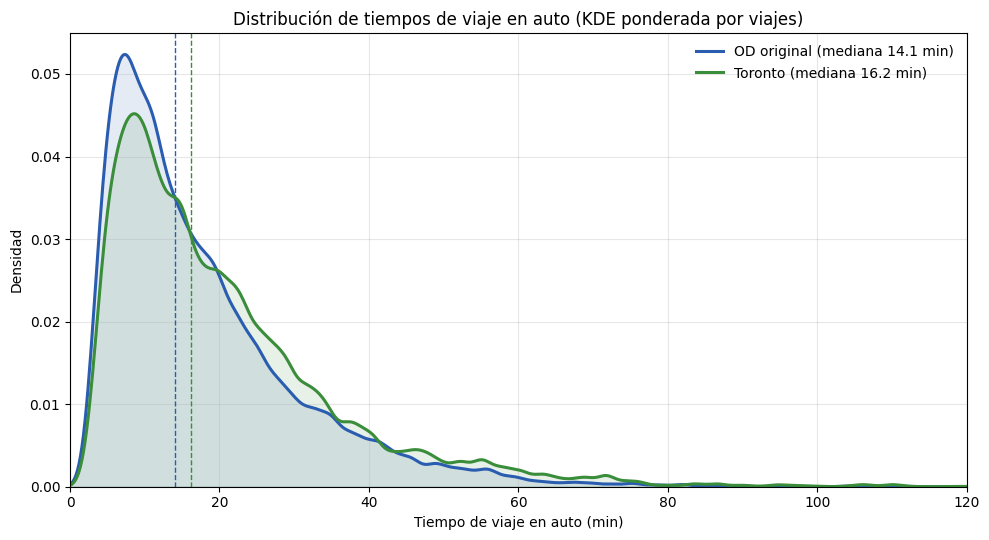

Ancho de banda usado (min): {'OD original': 1.0, 'Toronto': 1.0}


In [17]:
DIR_SALIDA.mkdir(parents=True, exist_ok=True)
COLORES = {"OD original": "#2a5db0", "Toronto": "#3a8d3a"}
grid = np.linspace(0, GRID_MAX, 601)

fig, ax = plt.subplots(figsize=(10, 5.5))
kdes, bws = {}, {}
for esc, df in datos.groupby("escenario", sort=False):
    dens, bw = kde_ponderada(df["tiempo"], df["viajes"], grid, BANDWIDTH)
    kdes[esc], bws[esc] = dens, bw
    med = percentil_ponderado(df["tiempo"], df["viajes"], 50)[0]
    ax.plot(grid, dens, color=COLORES.get(esc), lw=2.2, label=f"{esc} (mediana {med:.1f} min)")
    ax.fill_between(grid, dens, color=COLORES.get(esc), alpha=0.12)
    ax.axvline(med, color=COLORES.get(esc), ls="--", lw=1)

ax.set_xlabel("Tiempo de viaje en auto (min)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de tiempos de viaje en auto (KDE ponderada por viajes)")
ax.set_xlim(0, GRID_MAX); ax.set_ylim(bottom=0)
ax.grid(alpha=0.3); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(DIR_SALIDA / "kde_tiempos_auto_total.png", dpi=200)
plt.show()

print("Ancho de banda usado (min):", {k: round(v, 2) for k, v in bws.items()})

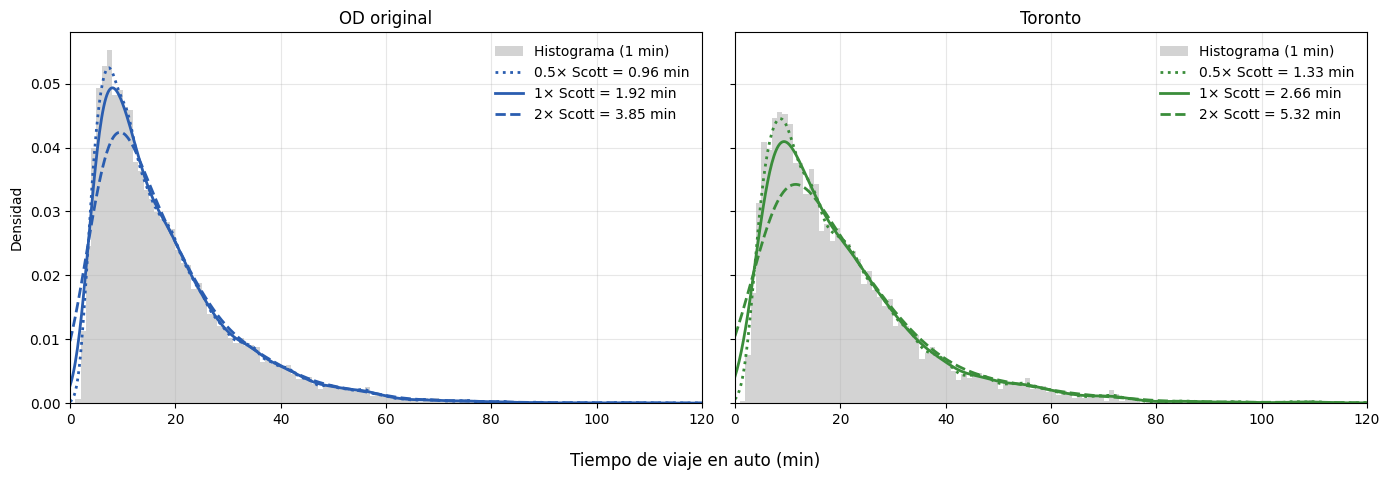

In [ ]:
# ============================================================
# Revisión del ancho de banda
# Compara la KDE con un histograma fino y con 3 anchos de banda distintos.
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (esc, df) in zip(axes, datos.groupby("escenario", sort=False)):
    x, w = df["tiempo"].to_numpy(), df["viajes"].to_numpy()
    bw_scott = ancho_banda_scott(x, w)

    # Histograma fino (cajitas de 1 min), ponderado por viajes, como referencia
    ax.hist(x, bins=np.arange(0, GRID_MAX + 1, 1), weights=w, density=True,
            color="lightgray", label="Histograma (1 min)")

    for factor, estilo in [(0.5, ":"), (1, "-"), (2, "--")]:
        dens, bw = kde_ponderada(x, w, grid, bw_scott * factor)
        ax.plot(grid, dens, ls=estilo, lw=2, color=COLORES.get(esc),
                label=f"{factor}× Scott = {bw:.2f} min")
    ax.set_title(esc); ax.set_xlim(0, GRID_MAX); ax.grid(alpha=0.3); ax.legend(frameon=False)
axes[0].set_ylabel("Densidad"); fig.supxlabel("Tiempo de viaje en auto (min)")
fig.tight_layout(); plt.show()

## Estadísticas para la interpretación

In [19]:
tabla_total = datos.groupby("escenario", sort=False)[["tiempo", "viajes"]].apply(resumen).T
if {"OD original", "Toronto"} <= set(tabla_total.columns):
    tabla_total["diferencia (Toronto - OD)"] = tabla_total["Toronto"] - tabla_total["OD original"]
tabla_total.to_csv(DIR_SALIDA / "resumen_total.csv")
tabla_total.round(2)

escenario,OD original,Toronto,diferencia (Toronto - OD)
viajes,1170691.15,1216870.91,46179.76
media_min,17.78,20.46,2.67
mediana_min,14.06,16.17,2.11
desv_est_min,13.01,15.40,2.39
p10,5.50,6.09,0.60
p25,8.33,9.46,1.13
p75,23.33,26.71,3.38
p90,35.37,39.91,4.54
IQR (p75-p25),15.00,17.25,2.25
%_viajes_<=15min,53.10,46.04,-7.06


In [20]:
tabla_periodo = (datos.groupby(["periodo", "escenario"], sort=False)[["tiempo", "viajes"]]
                      .apply(resumen)
                      [["viajes", "media_min", "mediana_min", "p90", "%_viajes_>30min"]])
tabla_periodo.to_csv(DIR_SALIDA / "resumen_por_periodo.csv")
tabla_periodo.round(2)

,,viajes,media_min,mediana_min,p90,%_viajes_>30min
periodo,escenario,,,,,
EM,OD original,8519.62,12.27,9.21,26.92,7.45
AP,OD original,345807.74,20.60,16.35,41.93,21.16
LM,OD original,163123.51,14.23,11.33,28.33,8.44
EA,OD original,285408.95,16.55,13.56,32.17,12.16
PP,OD original,280622.04,18.39,14.75,36.59,16.17
LN,OD original,87209.28,15.89,13.48,30.68,10.77
EM,Toronto,1153.20,16.09,15.90,27.03,3.86
AP,Toronto,381001.57,24.19,19.29,50.32,27.15
LM,Toronto,167109.08,15.63,12.75,31.20,10.80


## KDE por periodo

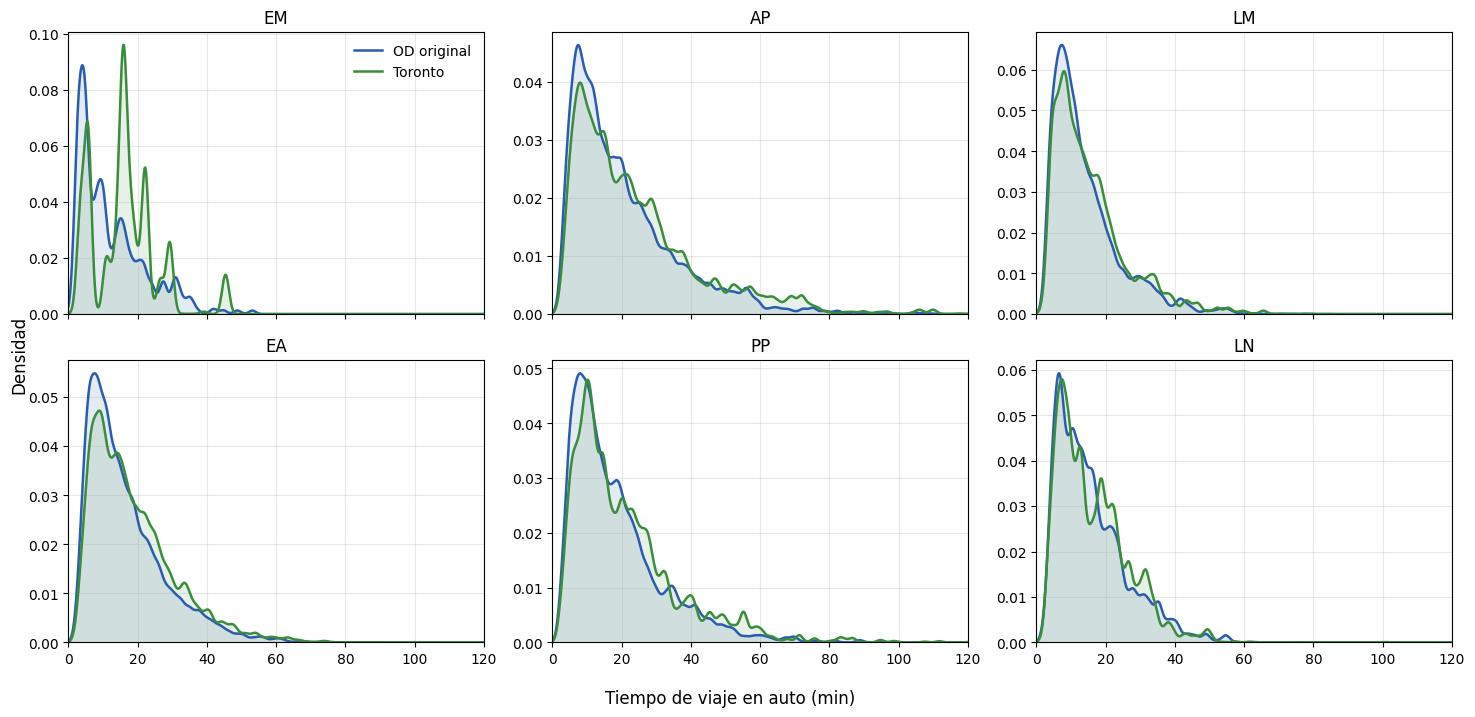

In [21]:
pers = list(dict.fromkeys(datos["periodo"]))
ncol = 3
nfil = int(np.ceil(len(pers) / ncol))
fig, axes = plt.subplots(nfil, ncol, figsize=(5 * ncol, 3.6 * nfil), sharex=True, squeeze=False)
for ax, per in zip(axes.flat, pers):
    for esc, df in datos[datos["periodo"] == per].groupby("escenario", sort=False):
        dens, _ = kde_ponderada(df["tiempo"], df["viajes"], grid, BANDWIDTH)
        ax.plot(grid, dens, color=COLORES.get(esc), lw=1.8, label=esc)
        ax.fill_between(grid, dens, color=COLORES.get(esc), alpha=0.12)
    ax.set_title(per); ax.set_xlim(0, GRID_MAX); ax.set_ylim(bottom=0); ax.grid(alpha=0.3)
for ax in list(axes.flat)[len(pers):]:
    ax.set_visible(False)
axes.flat[0].legend(frameon=False)
fig.supxlabel("Tiempo de viaje en auto (min)"); fig.supylabel("Densidad")
fig.tight_layout()
fig.savefig(DIR_SALIDA / "kde_tiempos_auto_por_periodo.png", dpi=200)
plt.show()